# 11 - Isolation Forest

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** Test whether an **unsupervised** anomaly detector can find phishing URLs without learning from phishing examples. We train an Isolation Forest, compare two ways of training it, compare feature sets, test the URL-only version on the external dataset, and find out which features it relies on.

**Input:** `data/processed/`

**Output:** `results/metrics/`, `results/confusion_matrices/`, `results/feature_importance/`

## Setup

We load the libraries and the shared functions from `src/`. Every team member uses the same functions, so all results are calculated in the same way and can be compared fairly.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import ParameterGrid

sys.path.append(str(Path("..").resolve()))
from src.data import PROCESSED_DIR, get_feature_sets, load_feature_groups, load_train_test, load_url_experiment, sample_rows
from src.evaluation import (
    RANDOM_STATE,
    evaluate_predictions,
    make_cv,
    plot_confusion_matrix,
    save_results,
    to_file_name,
)

In [2]:
X_train, X_test, y_train, y_test = load_train_test()
feature_sets = get_feature_sets()

print(f"Training set: {X_train.shape[0]:,} rows | {X_train.shape[1]} features")
print(f"Test set:     {X_test.shape[0]:,} rows | {X_test.shape[1]} features")

Training set: 188,296 rows | 69 features
Test set:     47,074 rows | 69 features


## How Isolation Forest Works

Isolation Forest builds many random trees. Each tree keeps splitting the data on a random feature at a random value until every URL is alone in its own leaf. **Unusual URLs are easy to separate, so they end up alone after only a few splits. Normal URLs sit among many similar URLs and need many splits.** The average number of splits becomes an *anomaly score*.

It does not use labels, so it cannot use `GridSearchCV` with F1 like the other models. Instead, we write our own small tuning loop and use the labels **only to score** the results.

**Two ways to train it.** We compare both, because the choice changes what the model learns:

- **`legit_only` (main approach):** train only on legitimate training URLs, so the model learns what *normal* looks like, and flags anything different. This is how anomaly detection is normally used (for example, learning normal network traffic).
- **`all`:** train on all training URLs without labels, as in the model template. The problem is that phishing is 42.7% of the data, which is not rare. Isolation Forest assumes anomalies are rare, so this should work worse.

**Settings we tune:**
- `n_estimators`: the number of trees.
- `max_samples`: how many URLs each tree is built from.
- `contamination`: the share of training URLs the model should treat as anomalies. This sets the cut-off. In `legit_only` mode it means "the share of legitimate URLs we accept as false alarms", so we try small values.

Isolation Forest splits on raw feature values, so it does not need scaling.

In [3]:
MODEL_NAME = "Isolation Forest"
TRAIN_MODE = "legit_only"
TUNING_SAMPLE_SIZE = 50000

param_grid = ParameterGrid({
    "n_estimators": [100, 300],
    "max_samples": [256, 1024],
    "contamination": [0.01, 0.05, 0.1, 0.2],
})


def fit_iforest(params, X, y, mode=TRAIN_MODE):
    """Fit an Isolation Forest. Labels are only used to choose which rows to train on."""
    X_fit = X[y == 0] if mode == "legit_only" else X
    return IsolationForest(**params, random_state=RANDOM_STATE, n_jobs=-1).fit(X_fit)


def anomaly_score(model, X):
    """Higher score = more unusual = more likely phishing."""
    return -model.score_samples(X)


def predict_phishing(model, X):
    """Isolation Forest returns -1 for anomalies. We turn this into 1 = Phishing, 0 = Legitimate."""
    return (model.predict(X) == -1).astype(int)


def evaluate_iforest(model, X, y):
    return evaluate_predictions(y, predict_phishing(model, X), anomaly_score(model, X))


def cv_iforest(params, X, y, folds, mode=TRAIN_MODE):
    scores = []
    for train_idx, val_idx in make_cv(folds).split(X, y):
        fold_model = fit_iforest(params, X.iloc[train_idx], y.iloc[train_idx], mode)
        scores.append(evaluate_iforest(fold_model, X.iloc[val_idx], y.iloc[val_idx]))
    return pd.DataFrame(scores)

## 1. Hyperparameter Tuning

We try every combination of settings with 3-fold cross-validation on a stratified sample of 50,000 training URLs. In each fold, the model is trained on the training part (legitimate URLs only) and scored on the validation part. We keep the combination with the best F1-score. The test set is not used here.

In [4]:
X_tune, y_tune = sample_rows(X_train, y_train, TUNING_SAMPLE_SIZE)

start = time.perf_counter()
tuning = []
for params in param_grid:
    scores = cv_iforest(params, X_tune, y_tune, folds=3)
    tuning.append({**params, "Mean F1": scores["F1"].mean(), "Mean ROC-AUC": scores["ROC-AUC"].mean()})

tuning = pd.DataFrame(tuning).sort_values("Mean F1", ascending=False).reset_index(drop=True)
best_params = {
    "n_estimators": int(tuning.loc[0, "n_estimators"]),
    "max_samples": int(tuning.loc[0, "max_samples"]),
    "contamination": float(tuning.loc[0, "contamination"]),
}
print(f"Tuning took {time.perf_counter() - start:.0f} seconds")
print(f"Best settings: {best_params}")
tuning.round(4)

Tuning took 38 seconds
Best settings: {'n_estimators': 300, 'max_samples': 1024, 'contamination': 0.1}


,contamination,max_samples,n_estimators,Mean F1,Mean ROC-AUC
0,0.10,1024,300,0.8800,0.9582
1,0.10,1024,100,0.8777,0.9584
2,0.05,1024,100,0.8533,0.9584
3,0.20,1024,100,0.8469,0.9584
4,0.20,1024,300,0.8464,0.9582
5,0.05,1024,300,0.8453,0.9582
6,0.20,256,300,0.8381,0.9448
7,0.10,256,100,0.8346,0.9429
8,0.20,256,100,0.8345,0.9429
9,0.10,256,300,0.8329,0.9448


## 2. Cross-Validation

We check the best settings with 5-fold stratified cross-validation on the same sample, and report the mean and standard deviation (Std) of each metric.

In [5]:
cv_table = cv_iforest(best_params, X_tune, y_tune, folds=5)
cv_results = cv_table.agg(["mean", "std"]).T.rename(columns={"mean": "Mean", "std": "Std"})
cv_results.round(4)

,Mean,Std
Accuracy,0.8958,0.0031
Precision,0.8680,0.0034
Recall,0.8916,0.0055
F1,0.8796,0.0037
ROC-AUC,0.9580,0.0035


## 3. Final Test

We train the model with the best settings on all legitimate URLs in the full training set and test it once on the test set.

In [6]:
start = time.perf_counter()
final_model = fit_iforest(best_params, X_train, y_train)
train_time = time.perf_counter() - start

test_results = evaluate_iforest(final_model, X_test, y_test)
print(f"Trained on {(y_train == 0).sum():,} legitimate URLs in {train_time:.1f} seconds")
pd.Series(test_results).round(4).to_frame("Test Score")

Trained on 107,880 legitimate URLs in 2.5 seconds


,Test Score
Accuracy,0.8989
Precision,0.8727
Recall,0.8935
F1,0.8830
ROC-AUC,0.9606


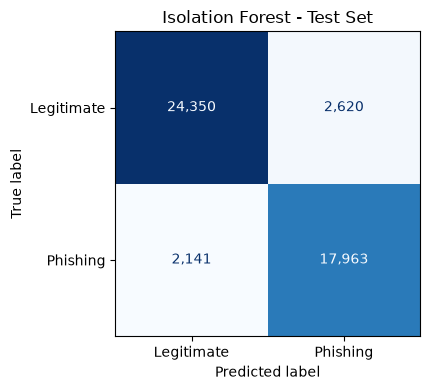

In [7]:
test_pred = predict_phishing(final_model, X_test)
plot_confusion_matrix(y_test, test_pred, f"{MODEL_NAME} - Test Set")

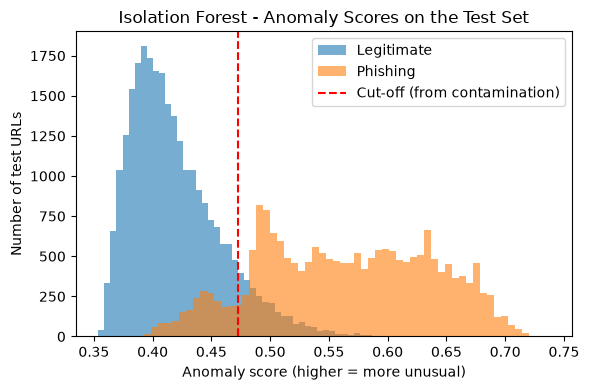

In [8]:
test_scores = anomaly_score(final_model, X_test)
threshold = -final_model.offset_

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(test_scores[y_test == 0], bins=60, alpha=0.6, label="Legitimate")
ax.hist(test_scores[y_test == 1], bins=60, alpha=0.6, label="Phishing")
ax.axvline(threshold, color="red", linestyle="--", label="Cut-off (from contamination)")
ax.set_xlabel("Anomaly score (higher = more unusual)")
ax.set_ylabel("Number of test URLs")
ax.set_title(f"{MODEL_NAME} - Anomaly Scores on the Test Set")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Training Mode Comparison

We now train the model the way the template suggests: on **all** training URLs, without using labels at all. We keep the same `n_estimators` and `max_samples`, and set `contamination` to the real share of phishing in the training set (42.7%), which is the best possible guess for this setting.

In [9]:
all_params = {**best_params, "contamination": round(float(y_train.mean()), 3)}
all_model = fit_iforest(all_params, X_train, y_train, mode="all")

mode_results = {
    "Trained on legitimate URLs only": test_results,
    "Trained on all URLs (no labels)": evaluate_iforest(all_model, X_test, y_test),
}
pd.DataFrame(mode_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
Trained on legitimate URLs only,0.8989,0.8727,0.8935,0.8830,0.9606
Trained on all URLs (no labels),0.4840,0.3955,0.3939,0.3947,0.4349


## 5. Feature Set Comparison

We train the same model on two smaller feature sets to answer two questions:

- **Original features only:** do our new features from feature engineering improve the model?
- **Without `URLSimilarityIndex`:** does the model still work without the strongest feature?

In [10]:
feature_results = {"All features": test_results}

for set_name in ["Original features only", "Without URLSimilarityIndex"]:
    features = feature_sets[set_name]
    set_model = fit_iforest(best_params, X_train[features], y_train)
    feature_results[set_name] = evaluate_iforest(set_model, X_test[features], y_test)

pd.DataFrame(feature_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
All features,0.8989,0.8727,0.8935,0.8830,0.9606
Original features only,0.8916,0.8715,0.8751,0.8733,0.9509
Without URLSimilarityIndex,0.8955,0.8693,0.8891,0.8791,0.9570


## 6. Experiment 2: URL Features Only

Here the model only uses the 18 URL features that we can create from any URL. We train it on legitimate PhiUSIIL URLs and test it on both the PhiUSIIL test set and the external dataset.

In [11]:
X_url_train, X_url_test, X_external, y_url_train, y_url_test, y_external = load_url_experiment()

url_model = fit_iforest(best_params, X_url_train, y_url_train)
url_results = {
    "PhiUSIIL test set": evaluate_iforest(url_model, X_url_test, y_url_test),
    "External dataset": evaluate_iforest(url_model, X_external, y_external),
}
pd.DataFrame(url_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
PhiUSIIL test set,0.7798,0.8201,0.6203,0.7064,0.8143
External dataset,0.6285,0.5961,0.8118,0.6874,0.7227


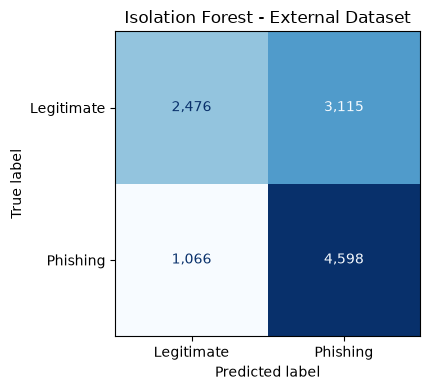

In [12]:
plot_confusion_matrix(y_external, predict_phishing(url_model, X_external), f"{MODEL_NAME} - External Dataset")

## 7. Prediction Speed

We measure how long the model takes to classify all test URLs.

In [13]:
start = time.perf_counter()
final_model.predict(X_test)
predict_time = time.perf_counter() - start

print(f"Training time:   {train_time:.2f} seconds")
print(f"Prediction time: {predict_time:.3f} seconds for {len(X_test):,} URLs "
      f"({predict_time / len(X_test) * 1e6:.1f} microseconds per URL)")

Training time:   2.46 seconds
Prediction time: 0.696 seconds for 47,074 URLs (14.8 microseconds per URL)


## 8. Which Features Does the Model Rely On?

We use **permutation importance**: we shuffle one feature at a time on the test set and see how much ROC-AUC drops. If the score drops a lot, the model was relying on that feature. We use a sample of 10,000 test URLs and repeat each shuffle 3 times. Because many features are correlated, we also shuffle **whole groups** of features at once.

In [14]:
get_score = anomaly_score

def permutation_auc_drop(model, X, y, groups, repeats=3):
    """Shuffle each group of columns together and measure how much ROC-AUC drops."""
    rng = np.random.default_rng(RANDOM_STATE)
    base = roc_auc_score(y, get_score(model, X))
    rows = {}
    for name, cols in groups.items():
        drops = []
        for _ in range(repeats):
            X_shuffled = X.copy()
            X_shuffled[cols] = X_shuffled[cols].values[rng.permutation(len(X_shuffled))]
            drops.append(base - roc_auc_score(y, get_score(model, X_shuffled)))
        rows[name] = {"AUC drop": np.mean(drops), "Std": np.std(drops)}
    return pd.DataFrame(rows).T.sort_values("AUC drop", ascending=False)

X_imp, y_imp = sample_rows(X_test, y_test, 10000)

start = time.perf_counter()
single_importance = permutation_auc_drop(final_model, X_imp, y_imp, {col: [col] for col in X_imp.columns})
print(f"Done in {time.perf_counter() - start:.0f} seconds")
single_importance.head(15).round(4)

Done in 35 seconds


,AUC drop,Std
PageQualityScore,0.0140,0.0002
HasCopyrightInfo,0.0138,0.0001
HasTitle,0.0121,0.0004
HasSocialNet,0.0113,0.0002
IsResponsive,0.0100,0.0001
HasDescription,0.0064,0.0000
HasSubmitButton,0.0050,0.0002
NoOfDegitsInURL,0.0048,0.0003
ExternalRefRatio,0.0046,0.0002
HasHiddenFields,0.0030,0.0001


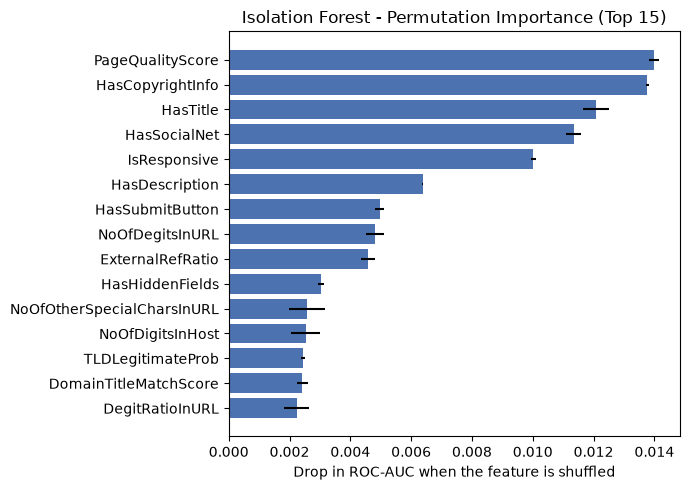

In [15]:
save_dir = Path("../results/feature_importance")
save_dir.mkdir(parents=True, exist_ok=True)

top = single_importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top["AUC drop"], xerr=top["Std"], color="#4C72B0")
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
ax.set_title(f"{MODEL_NAME} - Permutation Importance (Top 15)")
fig.tight_layout()
fig.savefig(save_dir / f"{to_file_name(MODEL_NAME)}.png", dpi=300)
plt.show()

In [16]:
groups = load_feature_groups()
group_importance = permutation_auc_drop(final_model, X_imp, y_imp, {
    "URLSimilarityIndex": ["URLSimilarityIndex"],
    "Other original features (47)": [col for col in groups["original"] if col != "URLSimilarityIndex"],
    "Engineered features (21)": groups["engineered"],
})
group_importance.round(4)

,AUC drop,Std
Other original features (47),0.2736,0.0048
Engineered features (21),0.0526,0.0016
URLSimilarityIndex,0.0000,0.0000


## 9. Where Does the Model Go Wrong?

We look at the URLs the model got wrong on the test set.

In [17]:
test_urls = pd.read_csv(PROCESSED_DIR / "test_urls.csv")["URL"].values
errors = pd.DataFrame({"URL": test_urls, "Actual": y_test.values, "Predicted": test_pred})

missed = errors[(errors["Actual"] == 1) & (errors["Predicted"] == 0)]
false_alarms = errors[(errors["Actual"] == 0) & (errors["Predicted"] == 1)]
print(f"Missed phishing URLs (false negatives): {len(missed):,}")
print(f"False alarms (false positives):         {len(false_alarms):,}")

Missed phishing URLs (false negatives): 2,141
False alarms (false positives):         2,620


In [18]:
print("Examples of missed phishing URLs:")
display(missed.sample(min(10, len(missed)), random_state=RANDOM_STATE)[["URL"]])
print("Examples of false alarms:")
display(false_alarms.sample(min(10, len(false_alarms)), random_state=RANDOM_STATE)[["URL"]])

Examples of missed phishing URLs:


,URL
42428,http://www.siwoulukdlik.com
37484,http://www.optimism.run
30835,http://www.bfgminer.org
44904,http://www.itaalabama.org
20543,http://www.wrapmobility.com
13226,http://www.fireblockstv.com
21278,http://www.primecaviar.com
5184,http://www.borjalnoor.com
36964,http://www.oakcourtpress.com
25930,http://www.classifoods.com


Examples of false alarms:


,URL
40523,https://www.artsfaculty.auckland.ac.nz
3384,https://www.noticiasaominuto.com.br
23022,https://www.alta-frequenza.corsica
26929,https://www.arethusa.qld.edu.au
44313,https://www.panamaamerica.com.pa
23581,https://www.centerforcopyrightintegrity.com
11262,https://www.baseball-statistics.com
41649,https://www.forabank.ru
44591,https://www.live95fm.ie
19975,https://www.cis-ca.org


In [19]:
def url_shape(urls):
    urls = pd.Series(urls)
    return pd.Series({
        "Avg URL length": urls.str.len().mean(),
        "Has a path (%)": urls.str.replace(r"^https?://", "", regex=True).str.contains("/.", regex=True).mean() * 100,
        "Uses HTTPS (%)": urls.str.startswith("https").mean() * 100,
    })

pd.DataFrame({
    "All phishing": url_shape(errors.loc[errors["Actual"] == 1, "URL"]),
    "Missed phishing": url_shape(missed["URL"]),
    "All legitimate": url_shape(errors.loc[errors["Actual"] == 0, "URL"]),
    "False alarms": url_shape(false_alarms["URL"]),
}).round(1)

,All phishing,Missed phishing,All legitimate,False alarms
Avg URL length,45.6,25.6,27.2,28.3
Has a path (%),28.5,4.0,0.0,0.0
Uses HTTPS (%),48.8,14.1,100.0,100.0


## 10. Save the Results

We save all results in one table. The comparison notebook will later load the tables of all models.

In [20]:
results = [
    {"Experiment": "Cross-validation", **cv_results["Mean"].to_dict()},
    {"Experiment": "Test set - All features", **test_results, "Train Time (s)": train_time, "Predict Time (s)": predict_time},
    {"Experiment": "Test set - Trained on all URLs (no labels)", **mode_results["Trained on all URLs (no labels)"]},
    {"Experiment": "Test set - Original features only", **feature_results["Original features only"]},
    {"Experiment": "Test set - Without URLSimilarityIndex", **feature_results["Without URLSimilarityIndex"]},
    {"Experiment": "URL features - PhiUSIIL test set", **url_results["PhiUSIIL test set"]},
    {"Experiment": "URL features - External dataset", **url_results["External dataset"]},
]

save_results(MODEL_NAME, results).round(4)

,Model,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s),Predict Time (s)
0,Isolation Forest,Cross-validation,0.8958,0.8680,0.8916,0.8796,0.9580,NaN,NaN
1,Isolation Forest,Test set - All features,0.8989,0.8727,0.8935,0.8830,0.9606,2.4596,0.6956
2,Isolation Forest,Test set - Trained on all URLs (no labels),0.4840,0.3955,0.3939,0.3947,0.4349,NaN,NaN
3,Isolation Forest,Test set - Original features only,0.8916,0.8715,0.8751,0.8733,0.9509,NaN,NaN
4,Isolation Forest,Test set - Without URLSimilarityIndex,0.8955,0.8693,0.8891,0.8791,0.9570,NaN,NaN
5,Isolation Forest,URL features - PhiUSIIL test set,0.7798,0.8201,0.6203,0.7064,0.8143,NaN,NaN
6,Isolation Forest,URL features - External dataset,0.6285,0.5961,0.8118,0.6874,0.7227,NaN,NaN


## 11. Findings

**1. Trained on legitimate URLs only, Isolation Forest works reasonably well without ever seeing a phishing example.** On the test set, it reaches an F1-score of **0.883** and a ROC-AUC of **0.961**. It finds 89% of phishing URLs (recall 0.894), and 87% of the URLs it flags are really phishing (precision 0.873). The cross-validation F1 (0.880 ± 0.004) is almost the same as the test F1, so the estimate is reliable. This is clearly below the supervised models (Naive Bayes reached an F1 of 0.9997), which is expected, because a supervised model learns from both classes.

**2. How the model is trained matters more than any setting.** When trained on all URLs without labels (the template's approach), the ROC-AUC drops to **0.435**, which is *worse than guessing*. Phishing makes up 42.7% of the data, so it is not rare. In this dataset, phishing pages are simple and look alike (few images, no copyright text, no social links), while real websites are each different. So, to Isolation Forest, **phishing pages look more "normal" than legitimate pages**. Isolation Forest only works here when we first teach it what legitimate pages look like.

**3. Tuning:** the best settings were 300 trees, 1,024 samples per tree and a contamination of 0.10. `max_samples = 1024` was clearly better than 256 (ROC-AUC 0.958 vs 0.944). The number of trees made almost no difference. `contamination` only moves the cut-off, so it changes F1 but not ROC-AUC. With 0.10, about 10% of legitimate URLs are flagged on purpose (2,620 false alarms on the test set), which is the price for finding 89% of phishing.

**4. Speed:** training took about 2.7 seconds and predicting 47,074 URLs about 0.8 seconds (about 16 microseconds per URL). That is slower than Naive Bayes but still fast enough for real-time use. (Times depend on the computer used.)

**5. `URLSimilarityIndex` has no effect on this model.** Removing it changes the F1-score only from 0.883 to 0.879, and shuffling it gives an importance of exactly 0. The reason: every legitimate URL in PhiUSIIL has the same `URLSimilarityIndex` value (100). Because we train only on legitimate URLs, this feature never changes in the training data, so the trees never split on it. This shows that Isolation Forest does not depend on the feature that makes the supervised models almost perfect.

**6. The new features helped a little.** With original features only, the F1-score is 0.873 and the ROC-AUC 0.951. With our engineered features, they are 0.883 and 0.961. This is a small gain, but it is larger than the cross-validation spread (± 0.004).

**7. The model relies on page-content features, and they work as a group.** Shuffling single features changes ROC-AUC by at most 0.014 (`PageQualityScore`, `HasCopyrightInfo`, `HasTitle`, `HasSocialNet`, `IsResponsive`). But shuffling all 47 other original features together drops ROC-AUC by **0.27**. Correlated features cover for each other when we shuffle only one, which is why the group test is needed. These results show what the model *relies on*, not what *causes* phishing.

**8. Where it goes wrong.** The 2,141 missed phishing URLs are short home-page URLs (only 4% have a path), so their URL looks like a legitimate one. Because the model relies on page features, a phishing page that copies the content of a real website (title, copyright text, social links) also looks normal to it.

**9. The URL-only version transfers better than expected.** With only the 18 URL features, the F1-score is 0.706 on the PhiUSIIL test set and **0.687 on the external dataset** (ROC-AUC 0.814 and 0.723). The Naive Bayes URL-only model dropped to a ROC-AUC of 0.499 on the external dataset. Isolation Forest does not learn a sharp rule like "a URL with a path is phishing". It only learns a rough idea of what normal URLs look like, which seems to carry over better to new data. This is still a weak result, and it is based on one external dataset only.

**Limitation:** "Unsupervised" is not fully true here, because we used the labels to select legitimate URLs for training and to tune the settings. In a real system, this means we need a clean list of known-good websites. Also, `contamination` must be chosen by hand, and it directly decides how many false alarms users see.

**Next step:** Use Isolation Forest as a second layer next to a supervised model, to flag new kinds of phishing that the supervised model has never seen.